###############################################################################
#           Aydin Loid Karatas
#           ---
#           University of Southern California
#           Department of Quantitative and Computational Biology
#           Mooney Lab
#           ---
#           draw_3T.py
###############################################################################

In [2]:
import pickle
import demesdraw
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

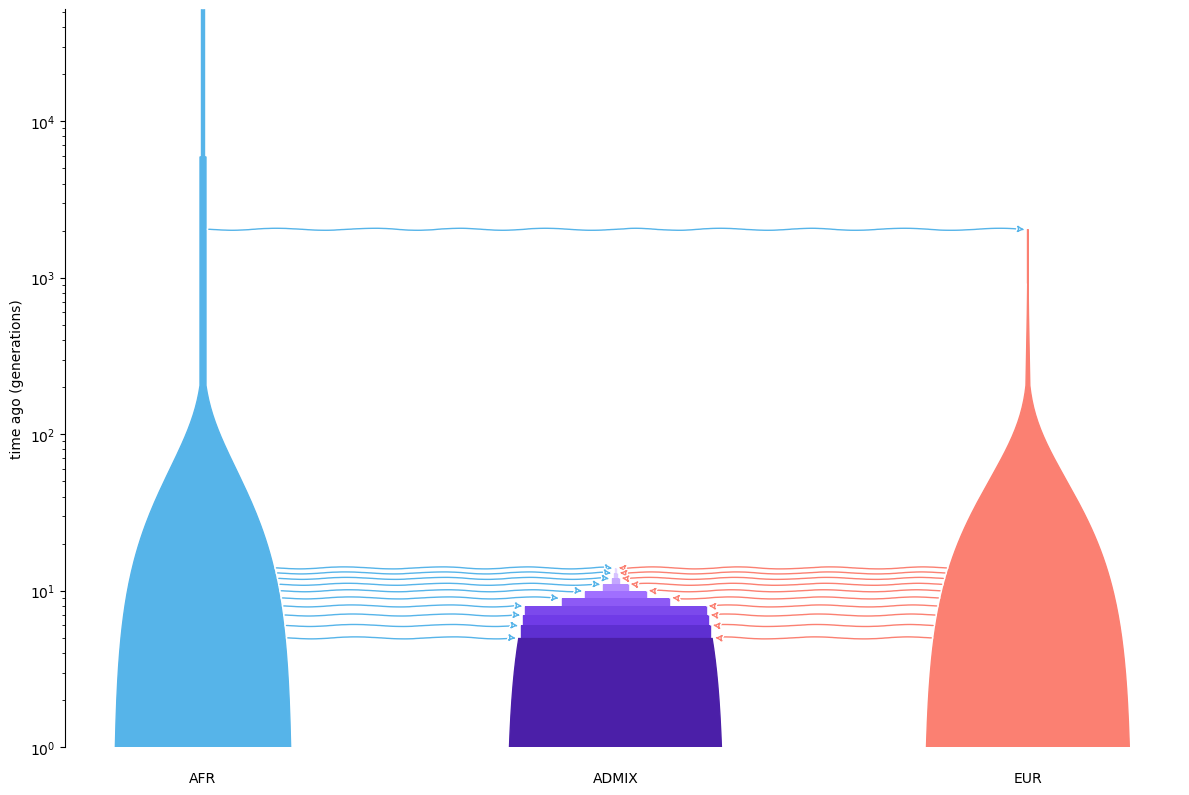

In [35]:
# load demography
demo_pkl = "/scratch1/karatas/msprime_runs_chr18_admix_3T/trees/HapMapII_GRCh38_1_all.demography.pkl"

with open(demo_pkl, "rb") as file:
    demo = pickle.load(file)

demo_graph = demo.to_demes()

# define population positions in drawn graph
positions = {
    "AFR": 0,

    "ADMIX_G1": 1_000_000,
    "ADMIX_G2": 1_000_000,
    "ADMIX_G3": 1_000_000,
    "ADMIX_G4": 1_000_000,

    "ADMIX": 1_000_000,

    "ADMIX_G5": 1_000_000,
    "ADMIX_G6": 1_000_000,
    "ADMIX_G7": 1_000_000,
    "ADMIX_G8": 1_000_000,
    "ADMIX_G9": 1_000_000,

    "EUR": 2_000_000,
}

# pop colors
colors = {
    "AFR": "#56B4E9",
    "EUR": "#fb8072",
}

# lavender/purple gradient from light -> dark
admix_gradient = [
    "#E6D9FF",
    "#D6C2FF",
    "#C4A6FF",
    "#B38BFF",
    "#A06FFF",
    "#8D5AF5",
    "#7C49EC",
    "#703BE7",
    "#5E2FD1",
]
for i in range(1, 10):
    colors[f"ADMIX_G{i}"] = admix_gradient[i - 1]
colors["ADMIX"] = "#4B1FA8"

# remove AFR <-> EUR migrataion lines for visualization
filtered_migrations = []
for mig in demo_graph.migrations:
    pair = {mig.source, mig.dest}
    if pair == {"AFR", "EUR"}:
        continue
    filtered_migrations.append(mig)
demo_graph.migrations = filtered_migrations

# plot
fig, ax = plt.subplots(figsize=(12, 8))
demesdraw.tubes(
    demo_graph,
    ax=ax,
    positions=positions,
    colours=colors,
    log_time=True,
    labels=None
)
ax.text(0, 0.6, "AFR", ha="center")
ax.text(1_000_000, 0.6, "ADMIX", ha="center")
ax.text(2_000_000, 0.6, "EUR", ha="center")
for artist in ax.get_children():
    if hasattr(artist, "set_alpha"):
        artist.set_alpha(1.0)

plt.tight_layout()
plt.show()